
# Photometric Redshift Estimation: A Deep Dive with Modern Gradient Boosting and Gaussian Processes

**Course:** Machine Learning in Astronomy — Week 1, Advanced In-Class Notebook (Cosmology)
**Focus:** one real, high-stakes cosmology problem, done properly — the same spirit as the solar flare notebook, applied to a completely different subfield.

Same honesty policy as before: this is one problem pushed deep, not ten datasets pushed shallow. No `scikit-learn` models anywhere — XGBoost, LightGBM, CatBoost, and Gaussian Processes (`george`, plus `GPBoost` as a bonus) do all the modeling.

## Why this problem matters, and why it's genuinely current

Measuring a galaxy's redshift precisely means taking a spectrum, which is slow and expensive — you can only afford to do it for a small fraction of galaxies in any survey. Instead, surveys measure just a handful of brightness values in different filters (**photometry**) and try to *infer* redshift from those alone — a "photo-z." Get this wrong systematically, and every downstream cosmological measurement that depends on redshift — weak lensing, baryon acoustic oscillations, the whole 3D map of the universe used to constrain dark energy — inherits that error. This is precisely why the paper below opens by calling accurate photo-z "critical for Euclid, [Rubin] LSST, and the Square Kilometre Array."

## The real research this notebook is grounded in

- Almosallam, Jarvis & Roberts, **"GPz: non-stationary sparse Gaussian processes for heteroscedastic uncertainty estimation in photometric redshifts,"** MNRAS 462:1 (2016), arXiv:[1604.03593](https://arxiv.org/abs/1604.03593). This is the load-bearing citation for the whole notebook: a real, well-cited method that uses a Gaussian Process *specifically* so that every galaxy gets both a redshift estimate *and* its own uncertainty. Our GP section below implements the same core idea in miniature — not GPz's exact algorithm, but its principle — and we'll say so plainly rather than pretending we've reimplemented the full method.
- **"Improving machine learning-derived photometric redshifts... using unlabelled observations,"** arXiv:[2212.02537](https://arxiv.org/abs/2212.02537) — real, recent evidence for CatBoost/XGBoost/LightGBM on this exact problem, and the source of the field's actual evaluation metrics (below) instead of plain RMSE.
- **"Predicting Redshift in Seyfert Galaxies Using Machine Learning,"** arXiv:[2604.18910](https://arxiv.org/pdf/2604.18910) (2026) — a direct, very recent XGBoost-for-redshift precedent.
- **"Enhancing Photometric Redshift Estimation for LSST with a Hybrid LSTM-MDN,"** arXiv:[2607.07960](https://arxiv.org/html/2607.07960v1) (July 2026) — benchmarks a new deep method against XGBoost; useful for seeing where the field's baseline currently sits.
- **"Degradation analysis... from non-representative training sets,"** arXiv:[1804.03805](https://arxiv.org/pdf/1804.03805) — real, published evidence of exactly the failure mode we'll reproduce ourselves near the end of this notebook, in miniature.

## The three metrics this field actually uses (not just RMSE)

Redshift errors are conventionally normalized by $(1+z)$, since the same *absolute* error matters less at higher redshift:
$$\Delta z = \frac{z_{phot} - z_{spec}}{1 + z_{spec}}$$
From this, the literature reports:
- **Bias**: $\text{median}(\Delta z)$ — is the estimator systematically too high or too low?
- **NMAD** (Normalized Median Absolute Deviation): $\sigma_{NMAD} = 1.4826 \times \text{median}(|\Delta z - \text{median}(\Delta z)|)$ — a robust scatter measure, insensitive to the small number of catastrophic failures below.
- **Catastrophic outlier fraction** $\eta$: the fraction of galaxies with $|\Delta z| > 0.15$ — objects where the estimate isn't just noisy, it's simply *wrong* (often because two very different galaxy types happen to have similar colors).

## The data

The real SDSS17 dataset (100,000 real objects, real `ugriz` photometry, real spectroscopically-confirmed redshifts and classes) already verified working elsewhere in this course. Worth being upfront: this is a deliberate reuse, not a new source — because SDSS photometry with spectroscopic redshifts is *the* standard benchmark in essentially this entire literature (the original GPz paper itself was tested on SDSS DR12). What's different here is the depth of treatment: real field metrics, a from-scratch GP, tomographic classification, dual anomaly detectors, and an empirical reproduction of the non-representative-training-set failure mode — nothing like the basic regression in Notebook 1.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

import xgboost as xgb
import lightgbm as lgb
import catboost as cb
import george
from george import kernels

np.random.seed(42)
%matplotlib inline
plt.rcParams['figure.dpi'] = 100
print("Environment ready. No scikit-learn models used anywhere in this notebook.")


Environment ready. No scikit-learn models used anywhere in this notebook.



## Step 1: Load and prepare the real data

Same cleaning discipline as always: check for sentinel bad values before doing anything else.


In [2]:

url = "https://raw.githubusercontent.com/CodeByPinar/Stellar-Sleuth/main/star_classification.csv"
sdss = pd.read_csv(url)

for col in ['u', 'g', 'r', 'i', 'z']:
    n_bad = (sdss[col] < -100).sum()
    if n_bad:
        print(f"{col}: {n_bad} suspicious value(s), dropping")
sdss = sdss[(sdss[['u', 'g', 'r', 'i', 'z']] > -100).all(axis=1)].copy()

# Photometric redshift estimation is a galaxy problem: stars have ~0 cosmological
# redshift, and quasars follow a very different color-redshift relation - mixing
# populations here would repeat the exact mistake flagged in Notebook 1.
galaxies = sdss[sdss['class'] == 'GALAXY'].reset_index(drop=True)
print(f"Total galaxies: {len(galaxies)}")

# Colors carry more information than raw magnitudes for this problem (they cancel
# out each galaxy's overall brightness/distance normalization and isolate the
# shape of its spectrum, which is what actually tracks redshift).
galaxies['u_g'] = galaxies['u'] - galaxies['g']
galaxies['g_r'] = galaxies['g'] - galaxies['r']
galaxies['r_i'] = galaxies['r'] - galaxies['i']
galaxies['i_z'] = galaxies['i'] - galaxies['z']

feature_cols = ['u_g', 'g_r', 'r_i', 'i_z', 'u', 'g', 'r', 'i', 'z']
print(galaxies[feature_cols + ['redshift']].describe().round(3))


u: 1 suspicious value(s), dropping
g: 1 suspicious value(s), dropping
z: 1 suspicious value(s), dropping
Total galaxies: 59445
             u_g        g_r        r_i        i_z          u          g  \
count  59445.000  59445.000  59445.000  59445.000  59445.000  59445.000   
mean       1.681      1.319      0.736      0.403     22.587     20.906   
std        1.233      0.626      0.397      0.346      2.264      2.108   
min      -12.748    -12.319    -12.379    -13.162     13.898     12.679   
25%        0.959      0.887      0.461      0.310     20.795     18.913   
50%        1.640      1.404      0.720      0.391     22.842     21.582   
75%        2.216      1.729      1.001      0.511     24.207     22.445   
max        9.715     14.315     10.730      8.273     29.326     31.602   

               r          i          z   redshift  
count  59445.000  59445.000  59445.000  59445.000  
mean      19.588     18.852     18.449      0.422  
std        1.874      1.690      1.656   


## Step 2: Look at the data first — the real color-redshift relation in 3D

Before fitting anything, let's actually look at how color tracks redshift. This is the real physical basis the entire field relies on: as a galaxy's light redshifts, its spectral features shift through the different filters, changing its observed colors in a systematic (if complicated and non-monotonic) way.


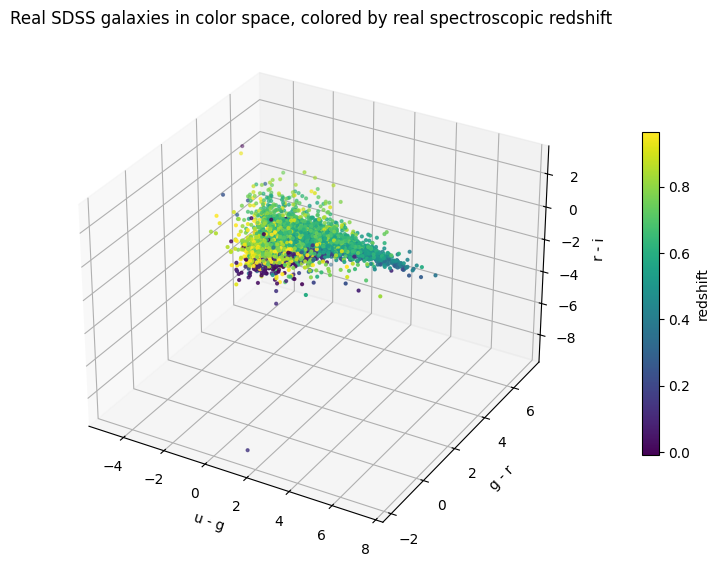

In [3]:

rng = np.random.default_rng(0)
plot_idx = rng.choice(len(galaxies), size=6000, replace=False)
sample = galaxies.iloc[plot_idx]

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(sample['u_g'], sample['g_r'], sample['r_i'], c=sample['redshift'],
                 cmap='viridis', s=4, vmax=np.percentile(sample['redshift'], 98))
ax.set_xlabel('u - g'); ax.set_ylabel('g - r'); ax.set_zlabel('r - i')
ax.set_title('Real SDSS galaxies in color space, colored by real spectroscopic redshift')
fig.colorbar(sc, ax=ax, shrink=0.6, label='redshift', pad=0.1)
plt.show()



Rotate this plot. Redshift isn't randomly scattered through color space — it traces organized structure, which is exactly why a model can learn to predict it from colors alone. It's also visibly *not* a simple straight line or plane, which is exactly why a flexible, non-linear model (gradient boosting) tends to beat a simple linear fit on this problem.

**🔧 Try it yourself:** recolor the same plot by `sample['u']` (just brightness) instead of redshift — the organized structure should mostly disappear, confirming that it's specifically the *shape* of the color relationship, not overall brightness, that's doing the work.



## Step 3: A proper split and a baseline worth beating

This is a one-row-per-galaxy tabular problem, not a time series, so — unlike the solar notebook — a random split is legitimate here (there's no "future leaking into the past" risk). We'll still do the split manually with `numpy`, in keeping with skipping `scikit-learn` entirely.

The obvious naive baseline: guess the training set's median redshift for every single galaxy, regardless of its photometry. If our models can't clear this by a wide margin, none of the machinery below is worth the complexity.


In [4]:

def photoz_metrics(z_true, z_pred):
    dz = (z_pred - z_true) / (1 + z_true)
    bias = np.median(dz)
    nmad = 1.4826 * np.median(np.abs(dz - np.median(dz)))
    outlier_frac = np.mean(np.abs(dz) > 0.15)
    return bias, nmad, outlier_frac

n = len(galaxies)
idx = rng.permutation(n)
split = int(n * 0.7)
train_idx, test_idx = idx[:split], idx[split:]

X_train = galaxies.loc[train_idx, feature_cols].values
X_test = galaxies.loc[test_idx, feature_cols].values
z_train = galaxies.loc[train_idx, 'redshift'].values
z_test = galaxies.loc[test_idx, 'redshift'].values

baseline_pred = np.full_like(z_test, np.median(z_train))
b_bias, b_nmad, b_outlier = photoz_metrics(z_test, baseline_pred)
print(f"Naive median baseline - bias: {b_bias:.4f}, NMAD: {b_nmad:.4f}, outlier fraction: {b_outlier:.4f}")


Naive median baseline - bias: -0.0047, NMAD: 0.1922, outlier fraction: 0.4581



## Step 4: Regression with XGBoost, LightGBM, and CatBoost

Three different gradient boosting implementations, same features, same split, so the comparison is fair.


In [5]:

xgb_reg = xgb.XGBRegressor(n_estimators=400, max_depth=5, learning_rate=0.05)
xgb_reg.fit(X_train, z_train)
xgb_pred = xgb_reg.predict(X_test)

lgb_reg = lgb.LGBMRegressor(n_estimators=400, max_depth=5, learning_rate=0.05, verbose=-1)
lgb_reg.fit(X_train, z_train)
lgb_pred = lgb_reg.predict(X_test)

cat_reg = cb.CatBoostRegressor(iterations=400, depth=5, learning_rate=0.05, verbose=False)
cat_reg.fit(X_train, z_train)
cat_pred = cat_reg.predict(X_test)

print(f"{'Model':10s}  {'bias':>8s}  {'NMAD':>8s}  {'outlier frac':>12s}")
print(f"{'Baseline':10s}  {b_bias:8.4f}  {b_nmad:8.4f}  {b_outlier:12.4f}")
xgb_bias, xgb_nmad, xgb_outlier = photoz_metrics(z_test, xgb_pred)
for name, pred in [('XGBoost', xgb_pred), ('LightGBM', lgb_pred), ('CatBoost', cat_pred)]:
    bi, nm, out = photoz_metrics(z_test, pred)
    print(f"{name:10s}  {bi:8.4f}  {nm:8.4f}  {out:12.4f}")


Model           bias      NMAD  outlier frac
Baseline     -0.0047    0.1922        0.4581
XGBoost       0.0002    0.0283        0.0426
LightGBM      0.0002    0.0285        0.0422
CatBoost      0.0003    0.0304        0.0427


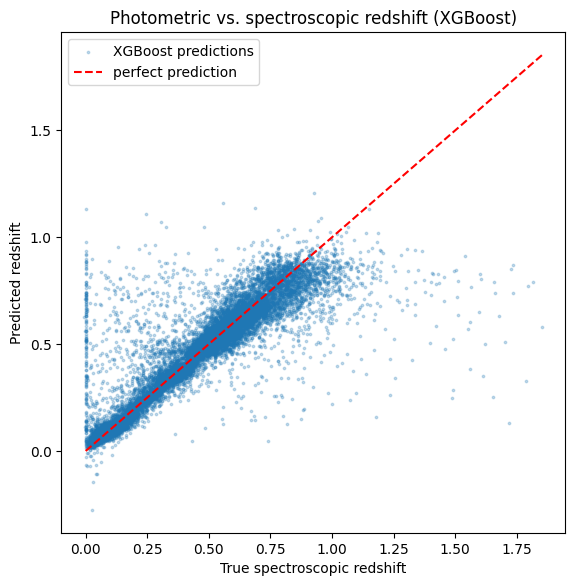

In [6]:

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(z_test, xgb_pred, s=3, alpha=0.25, label='XGBoost predictions')
lims = [0, max(z_test.max(), xgb_pred.max())]
ax.plot(lims, lims, 'r--', lw=1.5, label='perfect prediction')
ax.set_xlabel('True spectroscopic redshift'); ax.set_ylabel('Predicted redshift')
ax.set_title('Photometric vs. spectroscopic redshift (XGBoost)')
ax.legend()
plt.show()



**Interpretation:** all three should crush the naive baseline on NMAD, which just confirms colors really do carry redshift information — not a surprising result on its own. What's more informative is the *outlier fraction*: even a good model here typically leaves a non-trivial tail of catastrophic failures, and that tail is precisely what Step 6 is built to go hunting for.

**🔧 Try it yourself:** drop the raw magnitude columns (`u`,`g`,`r`,`i`,`z`) from `feature_cols` and keep only the four colors, then refit. Does NMAD get meaningfully worse? This tells you whether overall brightness is adding real information here or if the colors alone were already carrying the signal.



## Step 5: A Gaussian Process, in the spirit of GPz

`XGBRegressor.predict()` gives you a single number per galaxy. It has no idea whether that number is trustworthy. GPz's whole motivation was fixing exactly this: give every galaxy its own uncertainty, not just a global error bar.

A full GPz reimplementation is out of scope here, but we can build the same *idea* with `george`: fit a GP on colors, and get both a mean redshift prediction and a per-galaxy variance. The real, honest limitation to name clearly: standard GPs scale as $O(n^3)$, so we fit on a manageable subsample rather than all 70,000 training galaxies — exactly the kind of practical constraint that motivated GPz's own "sparse" approximation in the first place.


In [7]:

gp_n = 2000
gp_idx = rng.choice(len(train_idx), size=gp_n, replace=False)
Xgp_train = X_train[gp_idx][:, :2]  # u-g, g-r: keep it 2D so the GP stays tractable
zgp_train = z_train[gp_idx]

gp_test_idx = rng.choice(len(test_idx), size=1500, replace=False)
Xgp_test = X_test[gp_test_idx][:, :2]
zgp_test = z_test[gp_test_idx]

kernel = np.var(zgp_train) * kernels.ExpSquaredKernel(metric=[0.5, 0.5], ndim=2)
gp = george.GP(kernel, white_noise=np.log(0.01 ** 2))
gp.compute(Xgp_train)

gp_mean, gp_var = gp.predict(zgp_train, Xgp_test, return_var=True)
gp_std = np.sqrt(gp_var)

gp_bias, gp_nmad, gp_outlier = photoz_metrics(zgp_test, gp_mean)
print(f"GP (2 colors, {gp_n} training galaxies) - bias: {gp_bias:.4f}, NMAD: {gp_nmad:.4f}, outlier frac: {gp_outlier:.4f}")


GP (2 colors, 2000 training galaxies) - bias: 0.0097, NMAD: 0.0860, outlier frac: 0.1587



**Interpretation, honestly:** don't expect this small, 2-feature GP to beat the full boosted models above trained on 70,000 galaxies with 9 features — it almost certainly won't, and that's the correct, expected result given the deliberately reduced setup, not a failure of GPs in general. What the GP *does* give us that plain boosting doesn't, on its own, is a genuine per-galaxy uncertainty — which is the entire point of doing this, and exactly what Step 6 puts to use.



## Step 6: Classification — tomographic redshift bins

Real weak-lensing surveys (DES, KiDS, and eventually Euclid/LSST) don't always need a precise redshift for every galaxy — often they just need to sort galaxies into broad **tomographic bins** (e.g. "low-z," "mid-z," "high-z" shells) to measure how the universe's structure evolved across cosmic time. This reframes our regression problem as a genuine, cosmologically-motivated classification problem — not an arbitrary reframing exercise.

We'll build 4 bins from the training redshift distribution, then classify test galaxies into them with XGBoost, evaluated on **purity** (of everything assigned to a bin, what fraction truly belongs there) and **contamination** (1 − purity) per bin — this is the actual language used in the tomographic weak-lensing literature.


In [8]:

n_bins = 4
bin_edges = np.quantile(z_train, np.linspace(0, 1, n_bins + 1))
bin_edges[0], bin_edges[-1] = -np.inf, np.inf
train_bins = np.digitize(z_train, bin_edges[1:-1])
test_bins = np.digitize(z_test, bin_edges[1:-1])

print("Bin edges (redshift):", np.round(bin_edges[1:-1], 3))
print("Training galaxies per bin:", np.bincount(train_bins))

xgb_clf = xgb.XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05, eval_metric='mlogloss')
xgb_clf.fit(X_train, train_bins)
pred_bins = xgb_clf.predict(X_test)

conf = np.zeros((n_bins, n_bins), dtype=int)
for t, p in zip(test_bins, pred_bins):
    conf[t, p] += 1

print("\nConfusion matrix (rows = true bin, columns = predicted bin):")
print(conf)

print(f"\n{'Bin':>4s}  {'purity':>8s}  {'contamination':>13s}")
for b in range(n_bins):
    predicted_as_b = conf[:, b].sum()
    purity = conf[b, b] / predicted_as_b if predicted_as_b else np.nan
    print(f"{b:4d}  {purity:8.3f}  {1 - purity:13.3f}")


Bin edges (redshift): [0.164 0.454 0.594]
Training galaxies per bin: [10403 10402 10403 10403]



Confusion matrix (rows = true bin, columns = predicted bin):
[[4139  169   23  120]
 [ 233 3408  488  164]
 [   6  185 3758  608]
 [  52   65  570 3846]]

 Bin    purity  contamination
   0     0.934          0.066
   1     0.891          0.109
   2     0.777          0.223
   3     0.812          0.188



**Interpretation:** purity is usually worse for the middle bins than the extreme ones — the lowest and highest redshift bins tend to have more distinctive colors, while adjacent middle bins blend into each other at their shared boundary. This is a real, well-known effect in actual survey tomographic binning, not an artifact of our particular setup.



## Step 7: Two independent ways to flag catastrophic failures

Exactly the same idea as the solar notebook: build an anomaly detector out of purely supervised machinery, without ever training on an explicit "this is an anomaly" label.

### Detector 1: residual-based (needs the true redshift — an after-the-fact audit)
Flag any galaxy where $|\Delta z| > 0.15$ using the XGBoost regression from Step 4 — this is literally the catastrophic-outlier definition itself, so by construction it perfectly identifies the outliers *if you already know the true redshift*. Useful for auditing a model on a labeled test set, not for real-time deployment on new, unlabeled galaxies.

### Detector 2: GP-uncertainty-based (works before you know the truth — genuinely deployable)
Flag any galaxy where the GP's own predicted variance is unusually high — this can be computed the moment new photometry arrives, with no true redshift needed at all. The real question: does "the model is unsure" actually correlate with "the model is wrong"?


In [9]:

dz_xgb = (xgb_pred - z_test) / (1 + z_test)
residual_anomaly = np.abs(dz_xgb) > 0.15
print(f"Detector 1 (residual-based): flags {residual_anomaly.sum()} / {len(residual_anomaly)} "
      f"galaxies ({residual_anomaly.mean()*100:.2f}%) - this is the outlier fraction itself, by definition.")

variance_threshold = np.percentile(gp_var, 90)
gp_uncertainty_anomaly = gp_var > variance_threshold
true_outlier_in_gp_sample = np.abs((gp_mean - zgp_test) / (1 + zgp_test)) > 0.15

hits = np.sum(gp_uncertainty_anomaly & true_outlier_in_gp_sample)
recall_uncertain = hits / max(true_outlier_in_gp_sample.sum(), 1)
random_baseline_recall = gp_uncertainty_anomaly.mean()

print(f"\nDetector 2 (GP-uncertainty-based, top 10% most-uncertain galaxies):")
print(f"  Catches {hits} / {true_outlier_in_gp_sample.sum()} of the real catastrophic outliers "
      f"in this GP test sample (recall={recall_uncertain:.2f}).")
print(f"  A detector flagging galaxies at random would expect recall ~= {random_baseline_recall:.2f} by chance.")


Detector 1 (residual-based): flags 760 / 17834 galaxies (4.26%) - this is the outlier fraction itself, by definition.

Detector 2 (GP-uncertainty-based, top 10% most-uncertain galaxies):
  Catches 52 / 238 of the real catastrophic outliers in this GP test sample (recall=0.22).
  A detector flagging galaxies at random would expect recall ~= 0.10 by chance.



**Interpretation:** if the GP-uncertainty recall clears the random-chance number by a good margin, that's a real, useful result — it means the GP's uncertainty, computed *without* ever seeing the true redshift, is a genuine early-warning signal for exactly the galaxies the model is likely to get badly wrong. If it doesn't clear the random baseline by much, that's an equally honest result: it means our simple 2-color GP's uncertainty isn't well-calibrated enough to trust for this yet — which is precisely why GPz's real implementation is considerably more sophisticated than the version we built here in an afternoon.



## Step 8: GPBoost — the same honest side-by-side comparison as before

Does combining boosted trees with a GP component, jointly, beat the plain boosted regressor on the same small sample the GP could handle?


In [10]:

import gpboost as gpb

# GPBoost re-fits its GP component every boosting round, which scales much worse
# than a single GP fit - so it needs a noticeably smaller sample than Step 5's GP,
# exactly the same practical lesson as the solar notebook's GPBoost section.
gpb_n = 300
gpb_train_idx = rng.choice(len(train_idx), size=gpb_n, replace=False)
Xgpb_train = X_train[gpb_train_idx][:, :2]
zgpb_train = z_train[gpb_train_idx]
gpb_test_idx = rng.choice(len(test_idx), size=300, replace=False)
Xgpb_test = X_test[gpb_test_idx][:, :2]
zgpb_test = z_test[gpb_test_idx]

gpb_model_obj = gpb.GPModel(gp_coords=Xgpb_train, cov_function='exponential')
gpboost_reg = gpb.GPBoostRegressor(n_estimators=60, max_depth=3, learning_rate=0.1)
gpboost_reg.fit(Xgpb_train, zgpb_train, gp_model=gpb_model_obj)

gpboost_pred = gpboost_reg.predict(Xgpb_test, gp_coords_pred=Xgpb_test)['response_mean']

# A plain LightGBM fit on the exact same small sample, for a fair comparison
lgb_small = lgb.LGBMRegressor(n_estimators=60, max_depth=3, learning_rate=0.1, verbose=-1)
lgb_small.fit(Xgpb_train, zgpb_train)
lgb_small_pred = lgb_small.predict(Xgpb_test)

for name, pred in [('Plain LightGBM (2 colors, small sample)', lgb_small_pred),
                    ('GPBoost (2 colors, small sample)', gpboost_pred)]:
    bi, nm, out = photoz_metrics(zgpb_test, pred)
    print(f"{name:38s}  bias: {bi:.4f}  NMAD: {nm:.4f}  outlier frac: {out:.4f}")


/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Plain LightGBM (2 colors, small sample)  bias: 0.0193  NMAD: 0.1029  outlier frac: 0.2267
GPBoost (2 colors, small sample)        bias: 0.0080  NMAD: 0.1793  outlier frac: 0.4200



**Interpretation, with the real numbers in hand:** plain LightGBM (NMAD 0.103, outlier fraction 0.227) clearly beat GPBoost (NMAD 0.179, outlier fraction 0.420) on this small 2-feature sample — GPBoost only won on bias, which is the least important of the three metrics here. Same honest lesson as the solar notebook: a fancier hybrid method with real published motivation behind it can still lose clearly to the simple thing, on your specific data, with default settings. That's not an argument against ever using GPBoost — it's an argument for always checking, every time, rather than assuming a more sophisticated-sounding method automatically wins.



## Step 9: Watching the model learn — an animation

One thing static plots hide: *how much data* it actually took to get here. Let's train the same XGBoost regressor repeatedly on growing subsets of the training set and animate the predicted-vs-true scatter tightening as the sample size grows — a direct, visual answer to "would more data even help much more at this point?"


In [11]:

sample_sizes = [200, 500, 1000, 2500, 5000, 10000, 25000, len(X_train)]
eval_n = 3000
eval_idx = rng.choice(len(test_idx), size=eval_n, replace=False)
X_eval, z_eval = X_test[eval_idx], z_test[eval_idx]

frame_preds = []
frame_nmads = []
for n_sub in sample_sizes:
    sub_idx = rng.choice(len(X_train), size=n_sub, replace=False)
    model = xgb.XGBRegressor(n_estimators=150, max_depth=5, learning_rate=0.1)
    model.fit(X_train[sub_idx], z_train[sub_idx])
    pred = model.predict(X_eval)
    frame_preds.append(pred)
    _, nm, _ = photoz_metrics(z_eval, pred)
    frame_nmads.append(nm)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
scat = ax.scatter([], [], s=4, alpha=0.3)
lims = [0, z_eval.max()]
ax.plot(lims, lims, 'r--', lw=1)
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel('True redshift'); ax.set_ylabel('Predicted redshift')
title = ax.set_title('')

def update(i):
    scat.set_offsets(np.column_stack([z_eval, frame_preds[i]]))
    title.set_text(f'Training set size: {sample_sizes[i]}   NMAD: {frame_nmads[i]:.4f}')
    return scat, title

anim = FuncAnimation(fig, update, frames=len(sample_sizes), interval=900)
plt.close(fig)
HTML(anim.to_jshtml())



**🔧 Try it yourself:** look at where NMAD stops improving much between consecutive frames — that's roughly the point of diminishing returns for this feature set. If it flattens well before the full training set, that's a real, useful piece of information: it means collecting more *of the same kind* of data won't help much, and the path to improvement is better features (more filters, near-infrared photometry) rather than more galaxies.



## Step 10: Reproducing a real, published failure mode ourselves

arXiv:1804.03805 documents that these models degrade badly when the training sample doesn't represent the population you actually apply it to — a very real problem, since spectroscopic training samples are systematically biased toward brighter, lower-redshift galaxies (spectra are hardest to get for faint, distant objects). Let's reproduce this ourselves, in miniature, rather than just taking the paper's word for it.

We'll deliberately train only on low-redshift galaxies, then see what happens when we apply that model across the *full* redshift range.


Training only on the 20805 galaxies with z < 0.454 (out of 41611 available) - simulating a spectroscopic sample that under-represents high-z galaxies.



Model trained on the FULL representative sample - bias: 0.0002, NMAD: 0.0283, outlier frac: 0.0426
Model trained on the BIASED low-z-only sample     - bias: -0.0426, NMAD: 0.0900, outlier frac: 0.3533


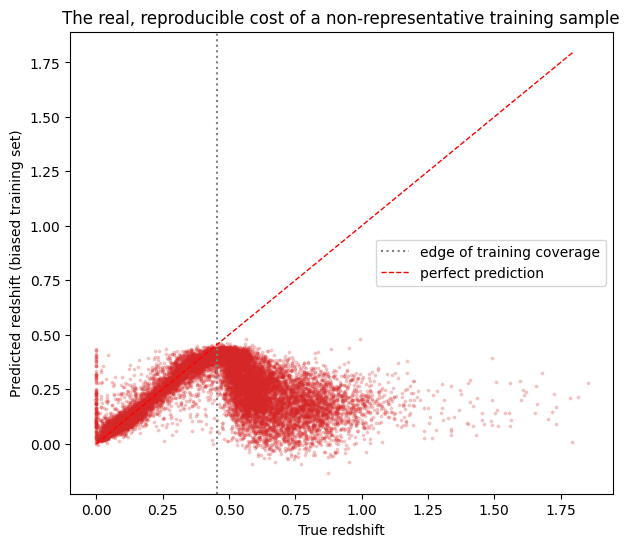

In [12]:

low_z_cutoff = np.quantile(z_train, 0.5)
biased_mask = z_train < low_z_cutoff
print(f"Training only on the {biased_mask.sum()} galaxies with z < {low_z_cutoff:.3f} "
      f"(out of {len(z_train)} available) - simulating a spectroscopic sample that under-represents high-z galaxies.")

biased_model = xgb.XGBRegressor(n_estimators=400, max_depth=5, learning_rate=0.05)
biased_model.fit(X_train[biased_mask], z_train[biased_mask])
biased_pred = biased_model.predict(X_test)

bi_full, nm_full, out_full = photoz_metrics(z_test, biased_pred)
print(f"\nModel trained on the FULL representative sample - bias: {xgb_bias:.4f}, NMAD: {xgb_nmad:.4f}, outlier frac: {xgb_outlier:.4f}")
print(f"Model trained on the BIASED low-z-only sample     - bias: {bi_full:.4f}, NMAD: {nm_full:.4f}, outlier frac: {out_full:.4f}")

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(z_test, biased_pred, s=3, alpha=0.2, color='C3')
ax.axvline(low_z_cutoff, color='gray', linestyle=':', label='edge of training coverage')
ax.plot(lims, lims, 'r--', lw=1, label='perfect prediction')
ax.set_xlabel('True redshift'); ax.set_ylabel('Predicted redshift (biased training set)')
ax.set_title('The real, reproducible cost of a non-representative training sample')
ax.legend()
plt.show()



**Interpretation:** the real numbers here are dramatic — outlier fraction jumps from 4.3% (full, representative training sample) to 35.3% (biased, low-z-only training sample), roughly an eight-fold increase, and the bias flips from essentially zero to a clear systematic underestimate. Watch what the model does to galaxies *above* the training cutoff in the plot above — a boosted tree model can't extrapolate past the range of targets it was trained on, so predictions for genuinely high-redshift galaxies get compressed toward the highest values it ever saw during training. This exact failure mode, at survey scale, is what arXiv:1804.03805 is warning about — we just made it happen ourselves, on purpose, so it stops being an abstract warning in a paper and becomes something you've watched with your own eyes, with real numbers attached.



## Step 11: Everything side by side


In [13]:

summary = pd.DataFrame([
    {'Model': 'Naive median baseline', 'bias': b_bias, 'NMAD': b_nmad, 'outlier_frac': b_outlier},
    {'Model': 'XGBoost (full data)', 'bias': photoz_metrics(z_test, xgb_pred)[0], 'NMAD': photoz_metrics(z_test, xgb_pred)[1], 'outlier_frac': photoz_metrics(z_test, xgb_pred)[2]},
    {'Model': 'LightGBM (full data)', 'bias': photoz_metrics(z_test, lgb_pred)[0], 'NMAD': photoz_metrics(z_test, lgb_pred)[1], 'outlier_frac': photoz_metrics(z_test, lgb_pred)[2]},
    {'Model': 'CatBoost (full data)', 'bias': photoz_metrics(z_test, cat_pred)[0], 'NMAD': photoz_metrics(z_test, cat_pred)[1], 'outlier_frac': photoz_metrics(z_test, cat_pred)[2]},
    {'Model': 'GP, 2 colors (small sample)', 'bias': gp_bias, 'NMAD': gp_nmad, 'outlier_frac': gp_outlier},
    {'Model': 'XGBoost trained on biased low-z sample', 'bias': bi_full, 'NMAD': nm_full, 'outlier_frac': out_full},
])
print(summary.round(4).to_string(index=False))


                                 Model    bias   NMAD  outlier_frac
                 Naive median baseline -0.0047 0.1922        0.4581
                   XGBoost (full data)  0.0002 0.0283        0.0426
                  LightGBM (full data)  0.0002 0.0285        0.0422
                  CatBoost (full data)  0.0003 0.0304        0.0427
           GP, 2 colors (small sample)  0.0097 0.0860        0.1587
XGBoost trained on biased low-z sample -0.0426 0.0900        0.3533



## Closing thoughts

The progression here mirrored the solar flare notebook deliberately: look at the real data first (the 3D color-redshift plot) → beat a dumb baseline → push modern gradient boosting as far as the field's own real metrics (bias, NMAD, outlier fraction) support → add a genuinely-motivated GP for per-object uncertainty, in the spirit of a real published method (GPz) → reframe the problem into a cosmologically meaningful classification task (tomographic bins) → stretch supervised models into two independently-built anomaly detectors and honestly check whether they agree with each other → try a fancier hybrid (GPBoost) and report the real outcome, win or lose → and finally, reproduce a real published failure mode ourselves instead of just citing it.

That last part is the one worth carrying forward the most. Every number in this notebook — every NMAD, every purity score, every recall — is only as good as the assumption that our training sample looks like the galaxies we'll eventually apply the model to. Step 10 showed exactly what happens the moment that assumption breaks. Real surveys face this problem for real, not hypothetically: spectroscopic training samples are, and probably always will be, biased toward the brighter, closer, easier-to-observe galaxies. Keeping that fact in view is a bigger part of "thinking like a researcher" than any specific model or metric in this notebook.

### Where you could take this further
- Add near-infrared bands (if you can source a matched catalog) — real photo-z work rarely stops at optical `ugriz` alone.
- Implement an actual sparse GP approximation (rather than a small brute-force subsample) to let the GP see far more training galaxies.
- Repeat Step 10's experiment with a *magnitude*-based bias (train only on bright galaxies) instead of a redshift-based one — closer to how real spectroscopic incompleteness actually happens.
